# Question:
### In a 20 turn game of Peach's Birthday Cake in Mario party 1, how far can I expect to move?

# Simulation:
### Random Variable (X): Dice roll
### One Trial: Roll the dice 20 times

In [30]:
import random
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib

In [33]:
# CONSTANTS and renaming
plt = matplotlib.pyplot

In [ ]:
def simulate_peachs_birthday_cake(turns=20, seed=None):
    """
    Simulates a 1-player 20-turn game on Peach's Birthday Cake (Mario Party 1).
    """
    if seed is not None:
        random.seed(seed)
        
    # Define Dice Spaces on the board layout
    DICE_SPACES = {1, 14, 21, 25, 35, 55}
    
    records = []
    current_space = 0
    total_roll_value = 0
    skip_next_turn = False
    global_roll_number = 0
    
    def step_forward(space):
        """Moves player forward 1 space, handling board forks and loops."""
        if space == 17:
            # 1 in 4 (25%) towards Bowser's Island; 3 in 4 (75%) towards Star/Toad path
            return 46 if random.random() < 0.25 else 18
        elif space == 45:
            # Reaches the end of base loop
            return 1
        elif space == 58:
            # Reaches the end of Bowser's Loop
            return 18
        else:
            return space + 1

    def advance_player(start_pos, steps):
        pos = start_pos
        for _ in range(steps):
            pos = step_forward(pos)
        return pos

    turn = 1
    while turn <= turns:
        turn_start_space = current_space
        
        # Handle skipped turn penalty
        if skip_next_turn:
            skip_next_turn = False
            global_roll_number += 1
            records.append({
                "Turn number": turn,
                "Roll Number": global_roll_number,
                "Roll Value": 0,
                "Is Extra Roll": False,
                "Is Lost Turn": True,
                "Space number at the start of the turn": turn_start_space,
                "Space number at the end of the turn": current_space,
                "total roll value so far": total_roll_value
            })
            turn += 1
            continue
            
        extra_rolls = 0
        roll_in_turn = 0
        
        while True:
            global_roll_number += 1
            is_extra = (roll_in_turn > 0)
            
            # Roll standard 1-10 die
            roll_val = random.randint(1, 10)
            total_roll_value += roll_val
            
            # Track space before individual roll
            space_at_roll_start = current_space
            current_space = advance_player(current_space, roll_val)
            
            records.append({
                "Turn number": turn,
                "Roll Number": global_roll_number,
                "Roll Value": roll_val,
                "Is Extra Roll": is_extra,
                "Is Lost Turn": False,
                "Space number at the start of the turn": turn_start_space,
                "Space number at the end of the turn": current_space,
                "total roll value so far": total_roll_value
            })
            
            # Check landing space effect (Dice Space / Mushroom)
            if current_space in DICE_SPACES:
                if random.random() < 0.5:
                    extra_rolls += 1  # Extra roll on this turn
                else:
                    skip_next_turn = True  # Lose next turn
            
            roll_in_turn += 1
            if extra_rolls > 0:
                extra_rolls -= 1
            else:
                break
                
        turn += 1

    return pd.DataFrame(records)

In [27]:
# Run 100 trials of the 20-turn simulation
all_trials = []

for trial in range(1, 101):
    # Run a single 20-turn simulation
    trial_df = simulate_peachs_birthday_cake(turns=20)
    
    # Add a column to keep track of the trial/simulation run number
    trial_df.insert(0, "Trial", trial)
    
    all_trials.append(trial_df)

# Combine all 100 trial DataFrames into one large DataFrame
df_all_trials = pd.concat(all_trials, ignore_index=True)

# Display the combined dataset
# df_all_trials

In [28]:
final_rolls = df_all_trials[df_all_trials["Turn number"] == 20].groupby("Trial")["total roll value so far"].max().tolist()
mean_roll = np.mean(final_rolls)
std_dev_roll = np.std(final_rolls, ddof=1)  # Sample standard deviation

print(f"Final Total Rolls List (First 10 shown): {final_rolls[:10]}")
print(f"Mean Final Total Roll: {mean_roll:.2f}")
print(f"Standard Deviation: {std_dev_roll:.2f}")

Final Total Rolls List (First 10 shown): [135, 111, 102, 94, 114, 111, 117, 106, 99, 103]
Mean Final Total Roll: 109.89
Standard Deviation: 15.17


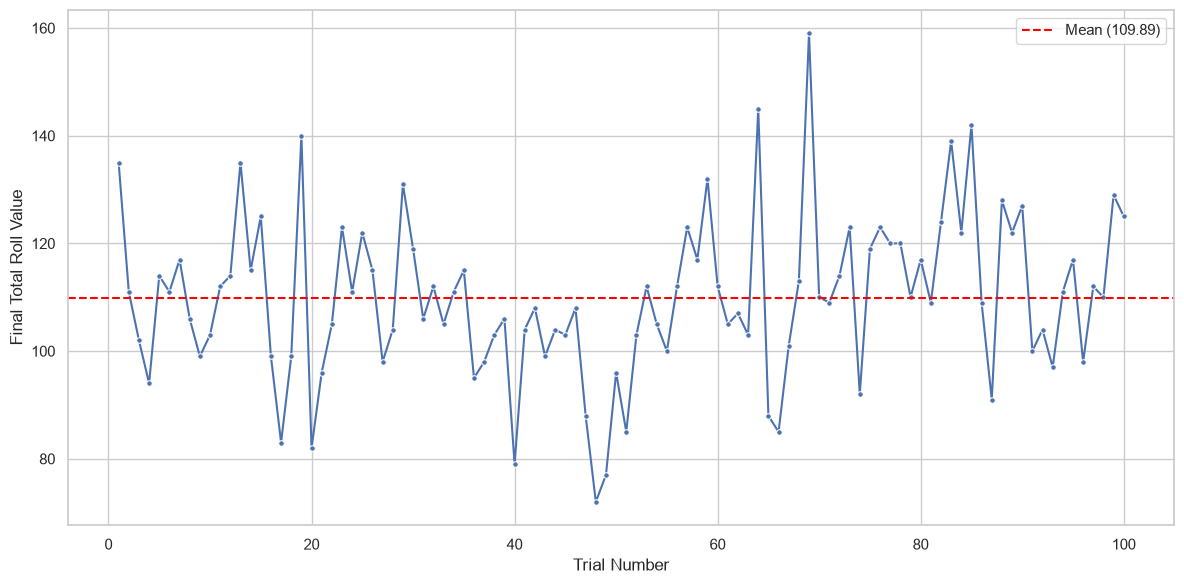

In [36]:
# Lineplot for final values
final_rolls_df = pd.DataFrame({
    'Trial': range(1, len(final_rolls) + 1),
    'Final Roll Value': final_rolls
})

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

ax = sns.lineplot(
    data=final_rolls_df,
    x='Trial',
    y='Final Roll Value',
    marker='o',
    color='b',
    linewidth=1.5,
    markersize=4
)

plt.xlabel("Trial Number", fontsize=12)
plt.ylabel("Final Total Roll Value", fontsize=12)

plt.axhline(mean_roll, color='red', linestyle='--', label=f'Mean ({mean_roll:.2f})')
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()